Shahlo Solieva

Updated 10/14/2026

**Figure 1A, 1C, 2B, S4** Averaging RMSF values over both chains, only HC, or only LC. 

Error bars are 95% confidence intervals from bootstrapped data (bootstraps = 1000, with replacement.) 

In [2]:
# Import all necessary packages.
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import mdtraj as md

# Set paths.
BASE_PATH = "/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/analysis/RMSF"
CLUSTER_BASE = "/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/analysis/clustering/radius_15_variable/data"
FIGURE_PATH = f"../figures/manuscript"

# Helper Functions

In [3]:
def get_residues(sys_path, vh_start, vh_end, vl_start, vl_end):
    """
    Return heavy and light chain residue names from variable regions.
    """
    pdb_path = f"{CLUSTER_BASE}/{sys_path}/prot_masses.pdb"
    pdb = md.load(pdb_path)
    ca_atoms = pdb.topology.select(
        f'chainid 0 and residue {vh_start} to {vh_end} and name CA '
        f'or chainid 1 and residue {vl_start} to {vl_end} and name CA')
    residues = [pdb.topology.atom(i).residue for i in ca_atoms]
    hc_residues = residues[:vh_end]
    lc_residues = residues[vh_end:]
    return hc_residues, lc_residues

def load_and_split_rmsf(system_name, vh_end, flipped=None):
    """
    Load rmsf for given system, split into hc and lc data. 
    """
    DATA_PATH = f"{BASE_PATH}/data/apo/{system_name}/VHC_VLC_CA_RMSF.npy"
    rmsf = np.load(DATA_PATH, allow_pickle=True)*10 
    if flipped: # if chain IDs are flipped! 
        lc = rmsf[:vh_end]
        hc = rmsf[vh_end:]
    else:
        hc = rmsf[:vh_end]
        lc = rmsf[vh_end:]
    return hc, lc

def calculate_95CI_and_split(system_name, vh_end, flipped=None):
    """
    Load bootstrapped (n=1000) rmsf for given system, split into hc and lc data. 
    """
    DATA_PATH = f"{BASE_PATH}/data/apo/{system_name}/n1000_bootstraps_VHC_VLC_CA_RMSF_avgs.npy"
    rmsfs_all_average = np.load(DATA_PATH)*10
    ci_low  = np.percentile(rmsfs_all_average, 2.5,  axis=0) 
    ci_high = np.percentile(rmsfs_all_average, 97.5, axis=0)  
    if flipped: # if chain IDs are flipped! 
        ci_lc   = [ci_low[:vh_end], ci_high[:vh_end]]  # ci low for HC, ci high for HC
        ci_hc   = [ci_low[vh_end:], ci_high[vh_end:]] 
    else: 
        ci_hc   = [ci_low[:vh_end], ci_high[:vh_end]]  # ci low for HC, ci high for HC
        ci_lc   = [ci_low[vh_end:], ci_high[vh_end:]] 
    return ci_hc, ci_lc 

def translate_resname_to_rescode(system_name, vh_start, vh_end, vl_start, vl_end):
    hc_resi, lc_resi = get_residues(f"apo/{system_name}", vh_start, vh_end, vl_start, vl_end)
    resname_to_rescode_definition =[[
        'ALA','ARG','ASN','ASP','CYS','GLU','GLN',\
        'GLY','HIS','ILE','LEU','LYS','MET','PHE',\
        'PRO','SER','THR','TRP','TYR','VAL'],\
        ['A'  ,'R'  ,'N'  ,'D'  ,'C'  ,'E'  ,'Q'  ,\
        'G'  ,'H'  ,'I'  ,'L'  ,'K'  ,'M'  ,'F'  ,\
        'P'  ,'S'  ,'T'  ,'W'  ,'Y'  ,'V' ]]
    single_code_resi_list = []
    for resi_list in [hc_resi, lc_resi]:
        single_code_resi_list_ = []
        for i in range(len(resi_list)):
            resname = str(resi_list[i])[0:3]
            res_number = str(resi_list[i])[3:]
            for j in range(len(resname_to_rescode_definition[0])):
                if resname == resname_to_rescode_definition[0][j]:
                    single_code_resi_list_.append(f'{resname_to_rescode_definition[1][j]}{res_number}')
        single_code_resi_list.append(single_code_resi_list_)
    return single_code_resi_list[0], single_code_resi_list[1]

In [4]:
def get_bar_info(Ab_ranges, flipped=None):
    if flipped:
        hc_rmsf, lc_rmsf =    load_and_split_rmsf(Ab_ranges[0], Ab_ranges[2], flipped=flipped)
        hc_ci,   lc_ci = calculate_95CI_and_split(Ab_ranges[0], Ab_ranges[2], flipped=flipped)  
    else: 
        hc_rmsf, lc_rmsf =    load_and_split_rmsf(Ab_ranges[0], Ab_ranges[2])
        hc_ci,   lc_ci = calculate_95CI_and_split(Ab_ranges[0], Ab_ranges[2])  
    
    avg_rmsf    = np.average(hc_rmsf)
    avg_ci_low  = np.average(hc_ci[0])
    avg_ci_high = np.average(hc_ci[1])
    errors = [avg_rmsf-avg_ci_low, avg_ci_high-avg_rmsf]
    hc_info = [avg_rmsf, errors ]

    avg_rmsf    = np.average(lc_rmsf)
    avg_ci_low  = np.average(lc_ci[0])
    avg_ci_high = np.average(lc_ci[1])
    errors = [avg_rmsf-avg_ci_low, avg_ci_high-avg_rmsf]
    lc_info = [avg_rmsf, errors ]

    avg_rmsf    = np.average(np.concatenate([hc_rmsf, lc_rmsf]))
    avg_ci_low  = np.average(np.concatenate([hc_ci[0], lc_ci[0]]))
    avg_ci_high = np.average(np.concatenate([hc_ci[1], lc_ci[1]]))
    errors = [avg_rmsf-avg_ci_low, avg_ci_high-avg_rmsf]
    hc_lc_info = [avg_rmsf, errors ]

    return hc_lc_info, hc_info, lc_info

def barplot_single_lineage_subplot(ax, lineage_name, bar_names, colors, which_chain, avgs, errs, combined=None):
    
    small_fontsize = 6
    ax.bar(bar_names, avgs, yerr=np.array(errs).T, 
           width=0.8, edgecolor='k', color=colors)

    ax.set_xticks(range(len(bar_names)))
    ax.tick_params(axis='y', labelsize=small_fontsize)
    ax.set_ylabel('Avg. CA RMSF ('+r'$\mathbf{\AA}$'+')',
                  fontsize=small_fontsize, weight='bold', labelpad=0)
    if combined:
        ax.set_title(f"{lineage_name}", 
                     fontsize=small_fontsize, weight='bold', pad=2)
        ax.set_xticklabels(bar_names, fontsize=small_fontsize, rotation=30)
    else:
        ax.set_title(f"Variable {which_chain} RMSF",
                 fontsize=small_fontsize, weight='bold', pad=2)
        ax.set_xlabel(f'{lineage_name} lineage',
                  fontsize=small_fontsize, weight='bold', labelpad=0)
        ax.set_xticklabels(bar_names, fontsize=small_fontsize)

# Each lineage

## CH103 lineage

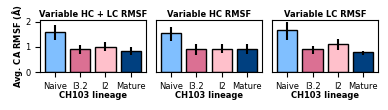

In [5]:
# Get data: 
Ab_ranges_list = [("CH103_naive_VC", 1, 121, 1, 108), ("CH103_I32_VC", 1, 121, 2, 108), 
                  ("CH103_I2_VC", 1, 121, 1, 108), ("CH103_mature_VC", 1, 121, 1, 105)]

hc_lc_rmsf_avg, hc_lc_rmsf_err = [], []
hc_rmsf_avg, hc_rmsf_err = [], []
lc_rmsf_avg, lc_rmsf_err = [], []
for Ab_ranges in Ab_ranges_list:
    hc_lc_info, hc_info, lc_info = get_bar_info(Ab_ranges)
    hc_lc_rmsf_avg.append(hc_lc_info[0])
    hc_lc_rmsf_err.append(hc_lc_info[1])
    hc_rmsf_avg.append(hc_info[0])
    hc_rmsf_err.append(hc_info[1])
    lc_rmsf_avg.append(lc_info[0])
    lc_rmsf_err.append(lc_info[1])

CH103_hc_lc_data = [hc_lc_rmsf_avg, hc_lc_rmsf_err]
# Plot data
lineage_name = 'CH103'
figure_name = lineage_name
bar_names = ['Naive','I3.2','I2','Mature']
colors = ['#80bfff','palevioletred','pink', '#004080']
fig, axes = plt.subplots(1, 3, figsize=(4, 1.2), sharey=True)
# Plot each dataset
barplot_single_lineage_subplot(axes[0], lineage_name, bar_names, colors, 'HC + LC', hc_lc_rmsf_avg, hc_lc_rmsf_err)
barplot_single_lineage_subplot(axes[1], lineage_name, bar_names, colors, 'HC', hc_rmsf_avg, hc_rmsf_err)
barplot_single_lineage_subplot(axes[2], lineage_name, bar_names, colors, 'LC', lc_rmsf_avg, lc_rmsf_err)
axes[1].set_ylabel('')
axes[2].set_ylabel('')
axes[0].set_yticks([0,1,2])
for i in range(1,3):
    axes[i].yaxis.set_visible(False)
plt.tight_layout()
plt.subplots_adjust(wspace=0.1)
plt.savefig(f"{FIGURE_PATH}/FigS4_RMSF_per_region_{figure_name}_SubBarPlots.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()

## CH65-CH67 lineage

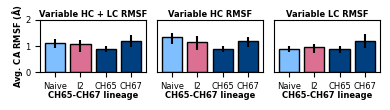

In [6]:
# Get data: 
Ab_ranges_list=[("CH65_naive_VC", 1, 126, 1, 108), 
                ("CH65_I2_VC", 1, 126, 1, 108), 
                ("CH65_mature_VC", 1, 126, 1, 108), 
                ("CH67_mature_VC", 1, 126, 1, 108)] 

hc_lc_rmsf_avg, hc_lc_rmsf_err = [], []
hc_rmsf_avg, hc_rmsf_err = [], []
lc_rmsf_avg, lc_rmsf_err = [], []
for Ab_ranges in Ab_ranges_list:
    hc_lc_info, hc_info, lc_info = get_bar_info(Ab_ranges)
    hc_lc_rmsf_avg.append(hc_lc_info[0])
    hc_lc_rmsf_err.append(hc_lc_info[1])
    hc_rmsf_avg.append(hc_info[0])
    hc_rmsf_err.append(hc_info[1])
    lc_rmsf_avg.append(lc_info[0])
    lc_rmsf_err.append(lc_info[1])
CH65_hc_lc_data = [hc_lc_rmsf_avg, hc_lc_rmsf_err]
# Plot data
lineage_name = 'CH65-CH67'
figure_name = lineage_name
bar_names = ['Naive','I2','CH65','CH67'] #'I2',
colors = ['#80bfff', 'palevioletred','#004080','#004080'] #palevioletred
fig, axes = plt.subplots(1, 3, figsize=(4, 1.2), sharey=True)
# Plot each dataset
barplot_single_lineage_subplot(axes[0], lineage_name, bar_names, colors, 'HC + LC', hc_lc_rmsf_avg, hc_lc_rmsf_err)
barplot_single_lineage_subplot(axes[1], lineage_name, bar_names, colors, 'HC', hc_rmsf_avg, hc_rmsf_err)
barplot_single_lineage_subplot(axes[2], lineage_name, bar_names, colors, 'LC', lc_rmsf_avg, lc_rmsf_err)
axes[1].set_ylabel('')
axes[2].set_ylabel('')
axes[0].set_yticks([0,1,2])
for i in range(1,3):
    axes[i].yaxis.set_visible(False)
plt.tight_layout()
plt.subplots_adjust(wspace=0.1)
plt.savefig(f"{FIGURE_PATH}/FigS4_RMSF_per_region_{figure_name}_SubBarPlots.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()

## 1-18 lineage

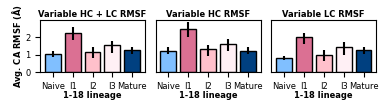

In [7]:
# Get data: 
Ab_ranges_list=[("Ab118_naive_VC", 1, 125, 1, 108),
                ("Ab118_I_VC", 1, 131, 1, 108),
                ("Ab118_IAb2748_VC", 1, 131, 1, 108),
                ("Ab118_IAb0923_VC", 1, 131, 1, 108),
                ("Ab118_mature_VC", 1, 131, 1, 108)]

hc_lc_rmsf_avg, hc_lc_rmsf_err = [], []
hc_rmsf_avg, hc_rmsf_err = [], []
lc_rmsf_avg, lc_rmsf_err = [], []
for Ab_ranges in Ab_ranges_list:
    hc_lc_info, hc_info, lc_info = get_bar_info(Ab_ranges)
    hc_lc_rmsf_avg.append(hc_lc_info[0])
    hc_lc_rmsf_err.append(hc_lc_info[1])
    hc_rmsf_avg.append(hc_info[0])
    hc_rmsf_err.append(hc_info[1])
    lc_rmsf_avg.append(lc_info[0])
    lc_rmsf_err.append(lc_info[1])

Ab118_hc_lc_data = [hc_lc_rmsf_avg, hc_lc_rmsf_err]
# Plot data
lineage_name = '1-18'
figure_name = lineage_name
bar_names = ['Naive','I1','I2','I3','Mature']
colors = ['#80bfff','palevioletred','pink','lavenderblush','#004080']
fig, axes = plt.subplots(1, 3, figsize=(4, 1.2), sharey=True)
# Plot each dataset
barplot_single_lineage_subplot(axes[0], lineage_name, bar_names, colors, 'HC + LC', hc_lc_rmsf_avg, hc_lc_rmsf_err)
barplot_single_lineage_subplot(axes[1], lineage_name, bar_names, colors, 'HC', hc_rmsf_avg, hc_rmsf_err)
barplot_single_lineage_subplot(axes[2], lineage_name, bar_names, colors, 'LC', lc_rmsf_avg, lc_rmsf_err)
axes[1].set_ylabel('')
axes[2].set_ylabel('')
axes[0].set_yticks([0,1,2])
for i in range(1,3):
    axes[i].yaxis.set_visible(False)
plt.tight_layout()
plt.subplots_adjust(wspace=0.1)
plt.savefig(f"{FIGURE_PATH}/FigS4_RMSF_per_region_{figure_name}_SubBarPlots.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()

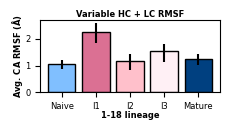

In [8]:
# Plot data
lineage_name = '1-18'
figure_name = lineage_name
bar_names = ['Naive','I1','I2','I3','Mature']
colors = ['#80bfff','palevioletred','pink','lavenderblush','#004080']
fig, axes = plt.subplots(1, 1, figsize=(2.4, 1.4))# , sharey=True)
barplot_single_lineage_subplot(axes, lineage_name, bar_names, colors, 'HC + LC', hc_lc_rmsf_avg, hc_lc_rmsf_err)
axes.set_yticks([0,1,2])
plt.tight_layout()
plt.subplots_adjust(wspace=0.1)
plt.savefig(f"{FIGURE_PATH}/Fig1C_RMSF_per_region_{figure_name}_SubBarPlot1.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()

## EPTC112 Lineage

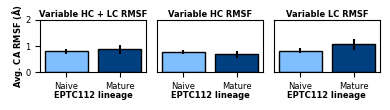

In [9]:
# Get data: 
Ab_ranges_list=[("EPTC112_naive_VC", 1, 121, 1, 110), 
                ("EPTC112_mature_VC", 1, 121, 1, 110)]

hc_lc_rmsf_avg, hc_lc_rmsf_err = [], []
hc_rmsf_avg, hc_rmsf_err = [], []
lc_rmsf_avg, lc_rmsf_err = [], []
for Ab_ranges in Ab_ranges_list:
    hc_lc_info, hc_info, lc_info = get_bar_info(Ab_ranges)
    hc_lc_rmsf_avg.append(hc_lc_info[0])
    hc_lc_rmsf_err.append(hc_lc_info[1])
    hc_rmsf_avg.append(hc_info[0])
    hc_rmsf_err.append(hc_info[1])
    lc_rmsf_avg.append(lc_info[0])
    lc_rmsf_err.append(lc_info[1])
EPTC112_hc_lc_data = [hc_lc_rmsf_avg, hc_lc_rmsf_err]
# Plot data
lineage_name = 'EPTC112'
figure_name = lineage_name
bar_names = ['Naive','Mature']
colors = ['#80bfff','#004080']
fig, axes = plt.subplots(1, 3, figsize=(4, 1.2), sharey=True)
# Plot each dataset
barplot_single_lineage_subplot(axes[0], lineage_name, bar_names, colors, 'HC + LC', hc_lc_rmsf_avg, hc_lc_rmsf_err)
barplot_single_lineage_subplot(axes[1], lineage_name, bar_names, colors, 'HC', hc_rmsf_avg, hc_rmsf_err)
barplot_single_lineage_subplot(axes[2], lineage_name, bar_names, colors, 'LC', lc_rmsf_avg, lc_rmsf_err)
axes[1].set_ylabel('')
axes[2].set_ylabel('')
axes[0].set_yticks([0,1,2])
for i in range(1,3):
    axes[i].yaxis.set_visible(False)
plt.tight_layout()
plt.subplots_adjust(wspace=0.1)
plt.savefig(f"{FIGURE_PATH}/FigS4_RMSF_per_region_{figure_name}_SubBarPlots.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()

## Anti-GD2, Ab 3F8

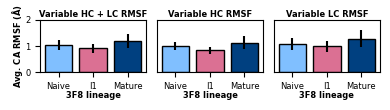

In [10]:
# Get data: 
Ab_ranges_list=[("Ab3F8_naive_VC", 1, 119, 1, 101), 
                ("Ab3F8_I56S_VC", 1, 119, 1, 101),
                ("Ab3F8_mature_VC", 1, 119, 1, 101)]

hc_lc_rmsf_avg, hc_lc_rmsf_err = [], []
hc_rmsf_avg, hc_rmsf_err = [], []
lc_rmsf_avg, lc_rmsf_err = [], []
for Ab_ranges in Ab_ranges_list:
    hc_lc_info, hc_info, lc_info = get_bar_info(Ab_ranges)
    hc_lc_rmsf_avg.append(hc_lc_info[0])
    hc_lc_rmsf_err.append(hc_lc_info[1])
    hc_rmsf_avg.append(hc_info[0])
    hc_rmsf_err.append(hc_info[1])
    lc_rmsf_avg.append(lc_info[0])
    lc_rmsf_err.append(lc_info[1])
Ab3F8_hc_lc_data = [hc_lc_rmsf_avg, hc_lc_rmsf_err]
# Plot data
lineage_name = '3F8'
figure_name = lineage_name
bar_names = ['Naive','I1','Mature']
colors = ['#80bfff','palevioletred','#004080']
fig, axes = plt.subplots(1, 3, figsize=(4, 1.2), sharey=True)
# Plot each dataset
barplot_single_lineage_subplot(axes[0], lineage_name, bar_names, colors, 'HC + LC', hc_lc_rmsf_avg, hc_lc_rmsf_err)
barplot_single_lineage_subplot(axes[1], lineage_name, bar_names, colors, 'HC', hc_rmsf_avg, hc_rmsf_err)
barplot_single_lineage_subplot(axes[2], lineage_name, bar_names, colors, 'LC', lc_rmsf_avg, lc_rmsf_err)
axes[1].set_ylabel('')
axes[2].set_ylabel('')
axes[0].set_yticks([0,1,2])
for i in range(1,3):
    axes[i].yaxis.set_visible(False)
plt.tight_layout()
plt.subplots_adjust(wspace=0.1)
plt.savefig(f"{FIGURE_PATH}/FigS4_RMSF_per_region_{figure_name}_SubBarPlots.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()

## PGT121-PGT124 lineage

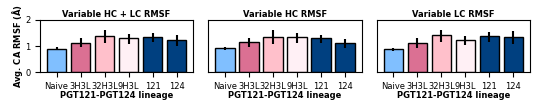

In [11]:
# Get data: 
Ab_ranges_list=[("PGT121_naive_kappa_VC",1, 132, 1, 109),
                ("PGT121_3H3L_VC",1, 132, 1, 112),
                ("PGT121_32H3L_VC",1, 132, 1, 112),
                ("PGT121_9H3L_VC",1, 132, 1, 112),
                ("PGT121_mature_kappa_VC", 1, 132, 1, 105), 
                ("PGT124_mature_VC", 1, 132, 1, 108)]

hc_lc_rmsf_avg, hc_lc_rmsf_err = [], []
hc_rmsf_avg, hc_rmsf_err = [], []
lc_rmsf_avg, lc_rmsf_err = [], []
for Ab_ranges in Ab_ranges_list:
    hc_lc_info, hc_info, lc_info = get_bar_info(Ab_ranges)
    hc_lc_rmsf_avg.append(hc_lc_info[0])
    hc_lc_rmsf_err.append(hc_lc_info[1])
    hc_rmsf_avg.append(hc_info[0])
    hc_rmsf_err.append(hc_info[1])
    lc_rmsf_avg.append(lc_info[0])
    lc_rmsf_err.append(lc_info[1])
PGT121_hc_lc_data = [hc_lc_rmsf_avg, hc_lc_rmsf_err]
# Plot data
lineage_name = 'PGT121-PGT124'
figure_name = lineage_name
bar_names = ['Naive','3H3L','32H3L','9H3L','121','124']
colors = ['#80bfff','palevioletred','pink','lavenderblush','#004080','#004080']
fig, axes = plt.subplots(1, 3, figsize=(5.5, 1.2), sharey=True)
# Plot each dataset
barplot_single_lineage_subplot(axes[0], lineage_name, bar_names, colors, 'HC + LC', hc_lc_rmsf_avg, hc_lc_rmsf_err)
barplot_single_lineage_subplot(axes[1], lineage_name, bar_names, colors, 'HC', hc_rmsf_avg, hc_rmsf_err)
barplot_single_lineage_subplot(axes[2], lineage_name, bar_names, colors, 'LC', lc_rmsf_avg, lc_rmsf_err)
axes[1].set_ylabel('')
axes[2].set_ylabel('')
axes[0].set_yticks([0,1,2])
for i in range(1,3):
    axes[i].yaxis.set_visible(False)
plt.tight_layout()
plt.subplots_adjust(wspace=0.1)
plt.savefig(f"{FIGURE_PATH}/FigS4_RMSF_per_region_{figure_name}_SubBarPlots.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()

### PGT121: lambda vs kappa LC

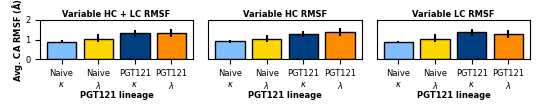

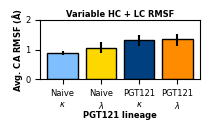

In [12]:
# Get data: 
Ab_ranges_list=[("PGT121_naive_kappa_VC",1, 132, 1, 109),
                ("PGT121_naive_lambda_VC",1, 132, 1, 109),
                ("PGT121_mature_kappa_VC", 1, 132, 1, 105), 
                ("PGT121_mature_lambda_VC", 1, 132, 1, 105)]

hc_lc_rmsf_avg, hc_lc_rmsf_err = [], []
hc_rmsf_avg, hc_rmsf_err = [], []
lc_rmsf_avg, lc_rmsf_err = [], []
for Ab_ranges in Ab_ranges_list:
    hc_lc_info, hc_info, lc_info = get_bar_info(Ab_ranges)
    hc_lc_rmsf_avg.append(hc_lc_info[0])
    hc_lc_rmsf_err.append(hc_lc_info[1])
    hc_rmsf_avg.append(hc_info[0])
    hc_rmsf_err.append(hc_info[1])
    lc_rmsf_avg.append(lc_info[0])
    lc_rmsf_err.append(lc_info[1])
PGT121_hc_lc_data = [hc_lc_rmsf_avg, hc_lc_rmsf_err]
# Plot data
lineage_name = 'PGT121'
figure_name = lineage_name

bar_names = ['Naive\n'+r'$\kappa$','Naive\n'+r'$\lambda$','PGT121\n'+r'$\kappa$','PGT121\n'+r'$\lambda$']
colors = ['#80bfff','gold','#004080','darkorange']
fig, axes = plt.subplots(1, 3, figsize=(5.5, 1.2), sharey=True)
# Plot each dataset
barplot_single_lineage_subplot(axes[0], lineage_name, bar_names, colors, 'HC + LC', hc_lc_rmsf_avg, hc_lc_rmsf_err)
barplot_single_lineage_subplot(axes[1], lineage_name, bar_names, colors, 'HC', hc_rmsf_avg, hc_rmsf_err)
barplot_single_lineage_subplot(axes[2], lineage_name, bar_names, colors, 'LC', lc_rmsf_avg, lc_rmsf_err)
axes[1].set_ylabel('')
axes[2].set_ylabel('')
axes[0].set_yticks([0,1,2])
for i in range(1,3):
    axes[i].yaxis.set_visible(False)
plt.tight_layout()
plt.subplots_adjust(wspace=0.1)
plt.savefig(f"../figures/RMSF_per_region_{figure_name}_kappa_lambda_SubBarPlots.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()

fig, axes = plt.subplots(1, 1, figsize=(2.2, 1.4), sharey=True)
barplot_single_lineage_subplot(axes, lineage_name, bar_names, colors, 'HC + LC', hc_lc_rmsf_avg, hc_lc_rmsf_err)
axes.set_yticks([0,1,2])
plt.tight_layout()
plt.subplots_adjust(wspace=0.1)
plt.savefig(f"{FIGURE_PATH}/Fig2B_RMSF_per_region_{figure_name}_kappa_lambda_SubBarPlot1.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()

## CAP256 lineage

### New

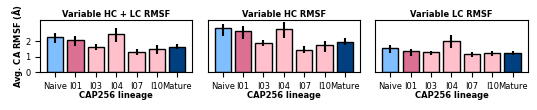

In [13]:
# Get data: 

#sys_paths=['apo/CAP256_naive_VC', 'apo/CAP256_I01_VC','apo/CAP256_I03_VC','apo/CAP256_I04_VC','apo/CAP256_I07_VC','apo/CAP256_I10_VC','apo/CAP256_mature_VC']
#sys_names=['Naive', 'I01','I03','I04','I07','I10','Mature']
#colors=['#80bfff','palevioletred','pink','pink','pink','pink', '#004080']

bar_names = ['Naive','I01','I03','I04','I07','I10','Mature'] #'I07','I10'
colors = ['#80bfff','palevioletred','pink','pink','pink','pink','#004080'] #'pink','pink'

Ab_ranges_list=[("CAP256_naive_VC",1, 144, 1, 111),
                ("CAP256_I01_VC",1, 144, 1, 111),
                ("CAP256_I03_VC",1, 144, 1, 111),
                ("CAP256_I04_VC",1, 144, 1, 111),
                ("CAP256_I07_VC",1, 111, 1, 144),
                 ("CAP256_I10_VC",1, 111, 1, 144),
                ("CAP256_mature_VC", 1, 145, 1, 111)] 
# ("CAP256_I01_VC",1, 144, 1, 111), #("CAP256_I04_VC",1, 144, 1, 111),
# ("CAP256_I03_VC",1, 144, 1, 111),
hc_lc_rmsf_avg, hc_lc_rmsf_err = [], []
hc_rmsf_avg, hc_rmsf_err = [], []
lc_rmsf_avg, lc_rmsf_err = [], []


Ab_ranges_list=[("CAP256_naive_VC",1, 144, 1, 111),
                ("CAP256_I01_VC",1, 144, 1, 111),
                ("CAP256_I03_VC",1, 144, 1, 111),
                ("CAP256_I04_VC",1, 144, 1, 111)]
for Ab_ranges in Ab_ranges_list:
    hc_lc_info, hc_info, lc_info = get_bar_info(Ab_ranges)
    hc_lc_rmsf_avg.append(hc_lc_info[0])
    hc_lc_rmsf_err.append(hc_lc_info[1])
    hc_rmsf_avg.append(hc_info[0])
    hc_rmsf_err.append(hc_info[1])
    lc_rmsf_avg.append(lc_info[0])
    lc_rmsf_err.append(lc_info[1])

Ab_ranges_list=[("CAP256_I07_VC",1, 111, 1, 144), ("CAP256_I10_VC",1, 111, 1, 144)]
for Ab_ranges in Ab_ranges_list:
    hc_lc_info, hc_info, lc_info = get_bar_info(Ab_ranges,'flipped')
    hc_lc_rmsf_avg.append(hc_lc_info[0])
    hc_lc_rmsf_err.append(hc_lc_info[1])
    hc_rmsf_avg.append(hc_info[0])
    hc_rmsf_err.append(hc_info[1])
    lc_rmsf_avg.append(lc_info[0])
    lc_rmsf_err.append(lc_info[1])

Ab_ranges_list=[("CAP256_mature_VC", 1, 145, 1, 111)]
for Ab_ranges in Ab_ranges_list:
    hc_lc_info, hc_info, lc_info = get_bar_info(Ab_ranges)
    hc_lc_rmsf_avg.append(hc_lc_info[0])
    hc_lc_rmsf_err.append(hc_lc_info[1])
    hc_rmsf_avg.append(hc_info[0])
    hc_rmsf_err.append(hc_info[1])
    lc_rmsf_avg.append(lc_info[0])
    lc_rmsf_err.append(lc_info[1])
   
CAP256_hc_lc_data = [hc_lc_rmsf_avg, hc_lc_rmsf_err]
# Plot data
lineage_name = 'CAP256'
figure_name = lineage_name
fig, axes = plt.subplots(1, 3, figsize=(5.5, 1.2), sharey=True)
# Plot each dataset
barplot_single_lineage_subplot(axes[0], lineage_name, bar_names, colors, 'HC + LC', hc_lc_rmsf_avg, hc_lc_rmsf_err)
barplot_single_lineage_subplot(axes[1], lineage_name, bar_names, colors, 'HC', hc_rmsf_avg, hc_rmsf_err)
barplot_single_lineage_subplot(axes[2], lineage_name, bar_names, colors, 'LC', lc_rmsf_avg, lc_rmsf_err)
axes[1].set_ylabel('')
axes[2].set_ylabel('')
axes[0].set_yticks([0,1,2])
for i in range(1,3):
    axes[i].yaxis.set_visible(False)
plt.tight_layout()
plt.subplots_adjust(wspace=0.1)
plt.savefig(f"{FIGURE_PATH}/FigS4_RMSF_per_region_{figure_name}_SubBarPlots.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()

# All lineages combined into one plot: Naive vs Mature

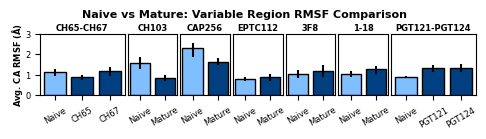

In [14]:
bar_names = ['Naive','Mature']
colors = ['#80bfff','#004080']

fig, axes = plt.subplots(1, 7, figsize=(5.0, 1.6), sharey=True,
                         gridspec_kw={'width_ratios': [1.7, 1, 1, 1, 1, 1, 1.7]} )
# Plot each dataset
#CH103_hc_lc_data = [hc_lc_rmsf_avg, hc_lc_rmsf_err]
barplot_single_lineage_subplot(axes[0], 'CH65-CH67', ['Naive','CH65','CH67'],  ['#80bfff','#004080','#004080'], 'Region', \
[CH65_hc_lc_data[0][0], CH65_hc_lc_data[0][-2], CH65_hc_lc_data[0][-1]], \
[CH65_hc_lc_data[1][0], CH65_hc_lc_data[1][-2], CH65_hc_lc_data[1][-1]], 'combined')

barplot_single_lineage_subplot(axes[1], 'CH103', bar_names, colors, 'Region', \
[CH103_hc_lc_data[0][0], CH103_hc_lc_data[0][-1]], \
[CH103_hc_lc_data[1][0], CH103_hc_lc_data[1][-1]], 'combined')

barplot_single_lineage_subplot(axes[2], 'CAP256', bar_names, colors, 'Region', \
[CAP256_hc_lc_data[0][0], CAP256_hc_lc_data[0][-1]], \
[CAP256_hc_lc_data[1][0], CAP256_hc_lc_data[1][-1]], 'combined')

barplot_single_lineage_subplot(axes[3], 'EPTC112', bar_names, colors, 'Region', \
[EPTC112_hc_lc_data[0][0], EPTC112_hc_lc_data[0][-1]], \
[EPTC112_hc_lc_data[1][0], EPTC112_hc_lc_data[1][-1]], 'combined')

barplot_single_lineage_subplot(axes[4], '3F8', bar_names, colors, 'Region', \
[Ab3F8_hc_lc_data[0][0], Ab3F8_hc_lc_data[0][-1]], \
[Ab3F8_hc_lc_data[1][0], Ab3F8_hc_lc_data[1][-1]], 'combined')

barplot_single_lineage_subplot(axes[5], '1-18', bar_names, colors, 'Region', \
[Ab118_hc_lc_data[0][0], Ab118_hc_lc_data[0][-1]], \
[Ab118_hc_lc_data[1][0], Ab118_hc_lc_data[1][-1]], 'combined')

barplot_single_lineage_subplot(axes[6], 'PGT121-PGT124', ['Naive','PGT121','PGT124'],  ['#80bfff','#004080','#004080'], 'Region', \
[PGT121_hc_lc_data[0][0], PGT121_hc_lc_data[0][-2], PGT121_hc_lc_data[0][-1]], \
[PGT121_hc_lc_data[1][0], PGT121_hc_lc_data[1][-2], PGT121_hc_lc_data[1][-1]], 'combined') 

axes[0].set_yticks([0,1,2,3])
for i in range(1,7):
    axes[i].yaxis.set_visible(False)

fig.suptitle('Naive vs Mature: Variable Region RMSF Comparison', fontsize=8, y=0.84, weight='bold')
plt.tight_layout()
plt.subplots_adjust(wspace=0.05)
plt.savefig(f"{FIGURE_PATH}/Fig1A_RMSF_per_region_Naive_Mature.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()